# 2. Exploration

We now look at the signals themselves, on the north cable first. You will:
1. convert the data to physical units,
2. compare three parts of the cable: on land, in shallow water and during the earthquake,
3. find where the earthquake energy lies with an FK transform, and keep only that part,
4. turn the record into what a Wood–Anderson seismometer would have shown,
5. pick the first arrival with an STA/LTA detector,
6. locate the earthquake and estimate its magnitude, with both cables.

On the way, you will write a few small functions. Notebook 3 reuses them.

In [1]:
# solutions only: run from the exercises folder
%cd ..

/home/trabatto/projects/indonesia/lmi-sir


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sp
import xdas as xd

from tools import locate, to_km

Start from the collection saved in notebook 1 (with the cable geometry).

In [3]:
abyss = xd.open("abyss.nc")
da = abyss["N"]
da

<xdas.DataArray (time: 24000, distance: 6664)>
VirtualSource: 610.1MB (float32)
Coordinates:
  * distance (distance): 0.000 to 102073.848
  * time (time): 2024-09-02T02:55:06.000 to 2024-09-02T02:59:05.990
    latitude (distance): [-29.89263556 ... -29.23606618]
    longitude (distance): [-71.25330943 ... -71.72586396]
    depth (distance): [   0.  ... 1339.1]

## Physical units

The interrogator measures how fast the phase of the backscattered light changes, per meter of
fiber: the unit is rad/(s·m). Stretching the fiber by a strain ε changes the phase by

$$\Delta\phi = \frac{4 \pi n \xi}{\lambda} \, \varepsilon \, L$$

over a length $L$ of fiber, with $\lambda$ the laser wavelength, $n$ the refractive index of the
fiber and $\xi$ the photoelastic factor of silica.

**Task:** compute the `gain` that converts the data from rad/(s·m) to strain rate (1/s).

| | value |
|---|---|
| $\lambda$ | 1536.6 nm |
| $n$ | 1.4677 |
| $\xi$ | 0.78 |

The interrogator stores the inverse of your result in its files (`header/sensitivities`):
9 362 208.9 rad/(strain·m).

In [4]:
wavelength = 1536.6e-9  # m
n = 1.4677
xi = 0.78
gain = wavelength / (4 * np.pi * n * xi)
gain

1.0681175917797704e-07

## Three parts of the cable

The first ~4.5 km of the cable are on land. Then the cable enters the sea and goes down to
~1500 m (look at `da["depth"]`). The earthquake arrives around 02:56:15.

**Task:** cut three tiles, load them and convert them to strain rate:
- **land**: 0–4.5 km, from 02:55:30 to 02:56:00;
- **shallow water**: 5–20 km, same time;
- **earthquake**: 20–90 km, from 02:56:10 to 02:56:40.

Which signals do you see on each tile?

> **Reminder:** `.sel` selects by coordinate value, `slice(start, end)` includes both ends.
> Times are written as strings. `.load()` reads the values into memory.
> ```python
> da.sel(distance=slice(1000, 2000), time=slice("2024-01-01T00:00:00", "2024-01-01T00:00:10"))
> ```

📖 [Indexing](https://xdas.readthedocs.io/en/stable/user-guide/data-structures/dataarray.html)

In [5]:
tiles = {
    "land": da.sel(distance=slice(0, 4500), time=slice("2024-09-02T02:55:30", "2024-09-02T02:56:00")),
    "shallow water": da.sel(distance=slice(5000, 20000), time=slice("2024-09-02T02:55:30", "2024-09-02T02:56:00")),
    "earthquake": da.sel(distance=slice(20000, 90000), time=slice("2024-09-02T02:56:10", "2024-09-02T02:56:40")),
}
tiles = {name: tile.load() * gain for name, tile in tiles.items()}

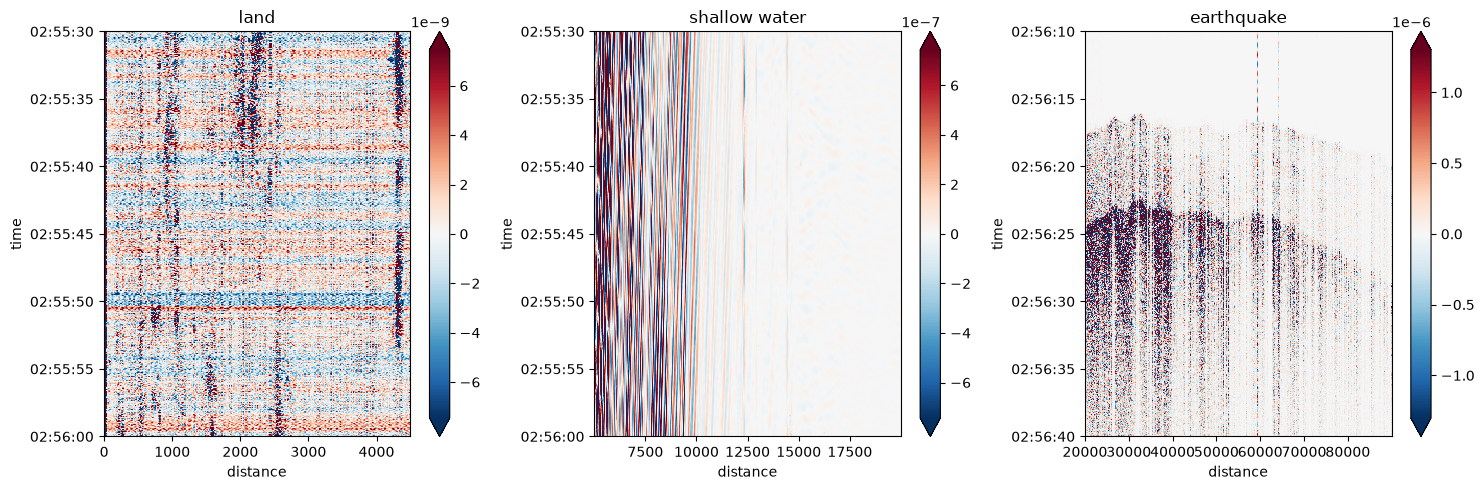

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, tile) in zip(axes, tiles.items()):
    tile.plot(ax=ax, robust=True, yincrease=False)
    ax.set_title(name)
fig.tight_layout()

## FK analysis

A 2D Fourier transform, in time and in distance, splits a tile into plane waves. Each wave
lands at a frequency $f$ (Hz) and a wavenumber $k$ (1/m), and its apparent speed along the
cable is $v = f / k$: waves of the same speed lie on a line through the origin.

**Task:** complete `compute_fk`: taper both dimensions (so the edges do not create artefacts),
then FFT the time into frequency (real FFT) and the distance into wavenumber. Return the
amplitude in dB.

> **Reminder:**
> ```python
> xd.taper(da, dim="x")                    # smooth window that goes to 0 at both ends of "x"
> xd.fft.rfft(da, dim={"x": "f"})          # real FFT: dimension "x" becomes "f" (f >= 0 only)
> xd.fft.fft(da, dim={"x": "f"})           # complex FFT: both signs of f
> 20 * np.log10(np.abs(da))                # amplitude in dB
> ```

📖 [`xdas.fft`](https://xdas.readthedocs.io/en/stable/api/fft.html)

In [7]:
def compute_fk(da):
    da = xd.taper(da, dim="time")
    da = xd.taper(da, dim="distance")
    da = xd.fft.rfft(da, dim={"time": "frequency"})
    da = xd.fft.fft(da, dim={"distance": "wavenumber"})
    return 20 * np.log10(np.abs(da))

**Task:** plot the FK of each tile. The dashed lines are the speed of sound in water
(1500 m/s) and a typical P-wave speed in the crust (6000 m/s).

Where is the energy of each tile? Which frequencies and wavenumbers should we keep for the
earthquake?

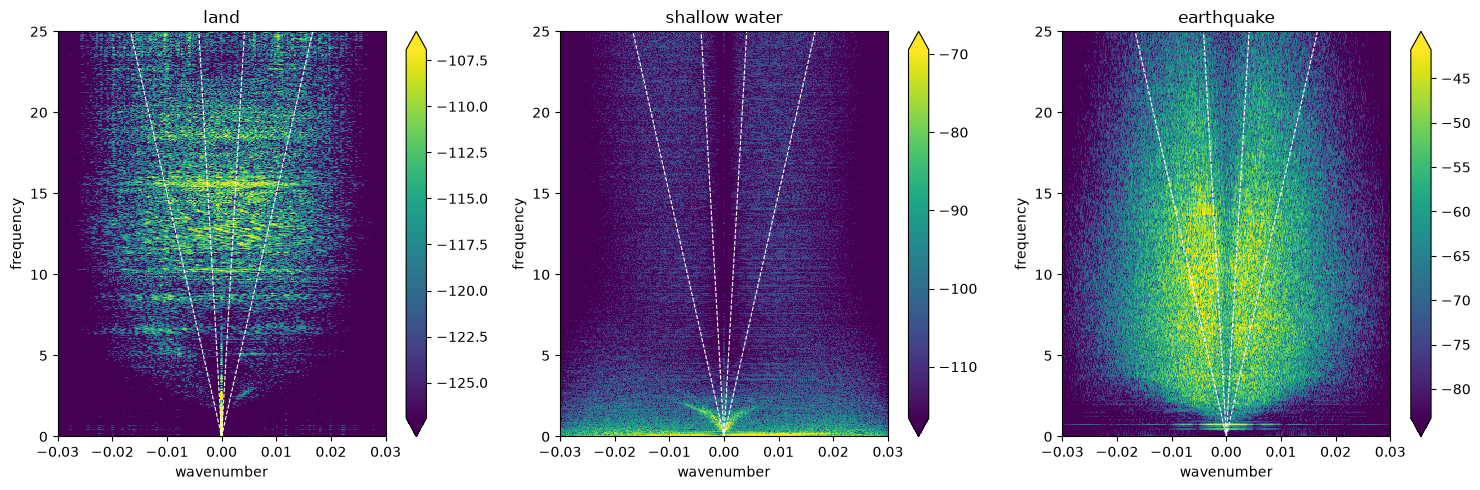

In [8]:
def plot_fk(fk, ax):
    vmin, vmax = np.percentile(fk.values, [50, 99.9])
    fk.plot(ax=ax, vmin=vmin, vmax=vmax)
    k = fk["wavenumber"].values
    for velocity in [1500, 6000]:
        ax.plot(k, velocity * np.abs(k), "w--", linewidth=0.8)
    ax.set_xlim(-0.03, 0.03)
    ax.set_ylim(0, 25)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, tile) in zip(axes, tiles.items()):
    fk = compute_fk(tile)
    plot_fk(fk, ax)
    ax.set_title(name)
fig.tight_layout()

## Filter and decimate

The earthquake energy lies between 2 and 15 Hz, and below 0.01 1/m in wavenumber (waves
slower than ~200 m/s along the cable are noise). Removing what lies outside this box also
lets us keep fewer samples: after the filter, nothing is left above 15 Hz, so a 50 Hz
sampling rate is enough; nothing is left above 0.01 1/m, so a channel every ~45 m is enough
(the Nyquist wavenumber is then 1 / (2 × 45 m) ≈ 0.011 1/m).

**Task:** complete `preprocess`: convert to strain rate, band-pass 2–15 Hz in time, low-pass
0.01 1/m in distance, then resample to 50 Hz in time and to ~45 m in distance.

> **Reminder:**
> ```python
> xd.filter(da, (1.0, 5.0), dim="x")      # band-pass between 1 and 5 (Hz if "x" is time)
> xd.filter(da, (None, 5.0), dim="x")     # low-pass below 5
> xd.filter(da, (1.0, None), dim="x")     # high-pass above 1
> xd.resample(da, 10.0, dim="x")                        # new sampling rate: 10 (Hz if "x" is time)
> xd.resample(da, interval=5.0, snap=True, dim="x")     # new sampling interval: ~5, keeping
>                                                       # existing samples (here one out of n)
> ```

📖 [`xdas.filter`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.filter.html) ·
[`xdas.resample`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.resample.html)

In [9]:
def preprocess(da):
    da = da * gain
    da = xd.filter(da, (2.0, 15.0), dim="time")
    da = xd.filter(da, (None, 0.01), dim="distance")
    da = xd.resample(da, 50.0, dim="time")
    da = xd.resample(da, interval=45.0, snap=True, dim="distance")
    return da

Apply it to one minute around the earthquake, from 5 km (the cable is then in the sea) to
97 km (the last channels are dead).

In [10]:
event = da.sel(time=slice("2024-09-02T02:56:00", "2024-09-02T02:57:00"), distance=slice(5000, 97000)).load()
processed = preprocess(event)
processed

<xdas.DataArray (time: 3001, distance: 2002)>
[[-4.812279e-11  4.160456e-09  1.357686e-09 ...  1.518849e-10
  -6.197195e-11  8.926630e-11]
 [-1.261052e-09  9.993181e-08  3.283133e-08 ...  2.370802e-09
  -1.134840e-10  1.526137e-09]
 [-2.531229e-09  2.196120e-07  7.014923e-08 ...  1.811617e-09
   2.314279e-09  4.630680e-09]
 ...
 [-3.456641e-10 -1.745007e-08 -7.189741e-09 ...  1.121719e-08
   2.356732e-09  8.395781e-09]
 [-5.979494e-10 -2.025385e-08 -4.304335e-09 ...  3.731432e-09
  -5.556334e-08 -3.040310e-08]
 [ 5.709651e-11 -1.344151e-08 -1.566866e-09 ... -1.768677e-08
  -5.952707e-08 -3.646094e-08]]
Coordinates:
  * distance (distance): 5009.477 to 96972.453
  * time (time): 2024-09-02T02:56:00.000 to 2024-09-02T02:57:00.000
    latitude (distance): [-29.88806179 ... -29.28069609]
    longitude (distance): [-71.27829776 ... -71.73284248]
    depth (distance): [   5.8 ... 1527.1]

The FK before and after: the red box is what we keep.

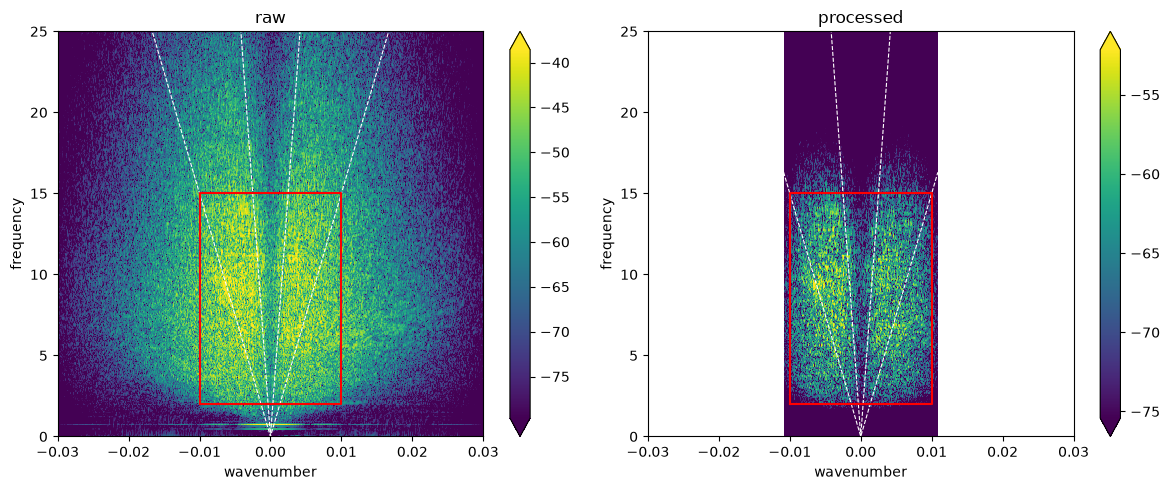

In [11]:
window = slice("2024-09-02T02:56:10", "2024-09-02T02:56:40")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title in zip(axes, [event * gain, processed], ["raw", "processed"]):
    plot_fk(compute_fk(data.sel(time=window)), ax)
    ax.plot([-0.01, 0.01, 0.01, -0.01, -0.01], [2, 2, 15, 15, 2], "r")
    ax.set_title(title)
fig.tight_layout()

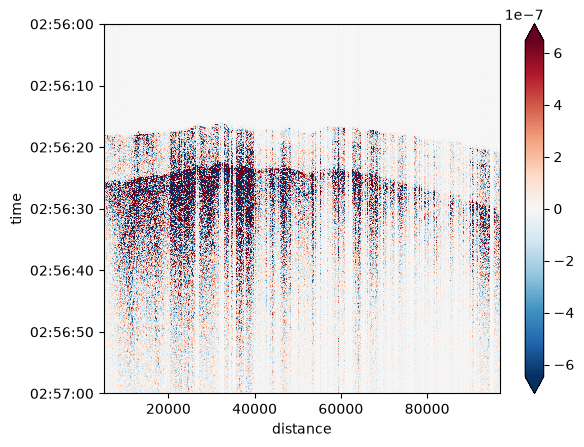

In [12]:
processed.plot(robust=True, yincrease=False)

## Wood–Anderson

The local magnitude ML was defined on the Wood–Anderson seismometer, which records ground
**displacement**. Its response is a high-pass filter at 1.25 Hz: above ~3 Hz it records the
displacement as it is (gain 1 in the IASPEI standard). Our data are already band-passed to
2–15 Hz, so the displacement is all we need: the Wood–Anderson response would change it by
less than 15 %.

To get the displacement along the cable from strain rate:
- integrating in time turns strain rate into strain;
- integrating strain along the cable gives the displacement along the cable, up to a constant
  that changes slowly with distance: remove it with a sliding mean of 2 km.

**Task:** complete `wood_anderson` with these three steps.

> **Reminder:**
> ```python
> xd.integrate(da, dim="x")                         # cumulative integral along "x"
> xd.sliding_mean_removal(da, wlen=100.0, dim="x")  # remove the mean over a sliding window
> ```

📖 [Convert to displacement](https://xdas.readthedocs.io/en/stable/user-guide/how-to/convert-displacement.html)

In [13]:
def wood_anderson(da):
    strain = xd.integrate(da, dim="time")
    deformation = xd.integrate(strain, dim="distance")
    return xd.sliding_mean_removal(deformation, wlen=2000.0, dim="distance")

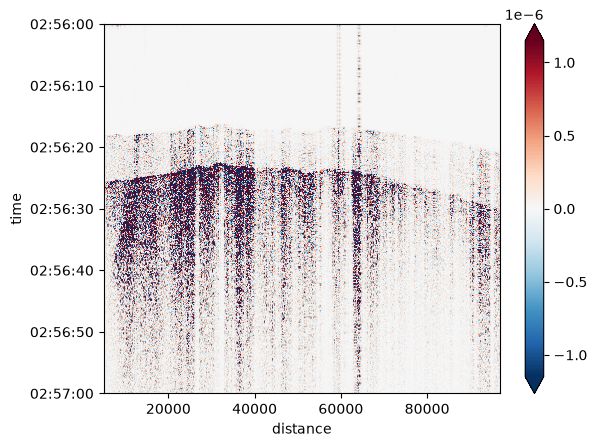

In [14]:
wa = wood_anderson(processed)
wa.plot(robust=True, yincrease=False)

## Picking with STA/LTA

The STA/LTA detector compares the short-term average (STA) of the signal energy with its
long-term average (LTA). On noise, the ratio stays around 1. When a wave arrives, the STA
rises first and the ratio jumps.

We use the recursive form: each new sample updates the averages, with no window to keep in
memory. For the energy $x_k^2$ and a duration $T$ (s) sampled every $\Delta t$:

$$a_k = c\, x_k^2 + (1 - c)\, a_{k-1}, \qquad c = \Delta t / T$$

**Task:** complete `stalta`: square the signal, compute the short average (duration `sta`)
and the long average (duration `lta`) with this recursion, and return their ratio.

> **Reminder:** `sp.lfilter(b, a, x, axis=0)` computes, along the first axis,
> `a[0] y[k] + a[1] y[k-1] = b[0] x[k]`. `da.values` gives the numpy array of a `DataArray`, and
> `da.copy(data=x)` puts a new array back with the same coordinates.

In [15]:
def stalta(da, sta, lta):
    dt = da["time"].get_sampling_interval()
    csta, clta = dt / sta, dt / lta
    power = da.values ** 2
    short = sp.lfilter([csta], [1, csta - 1], power, axis=0)
    long = sp.lfilter([clta], [1, clta - 1], power, axis=0)
    ratio = short / long
    ratio[: round(lta / dt)] = 0  # the long average is not settled yet
    return da.copy(data=ratio)

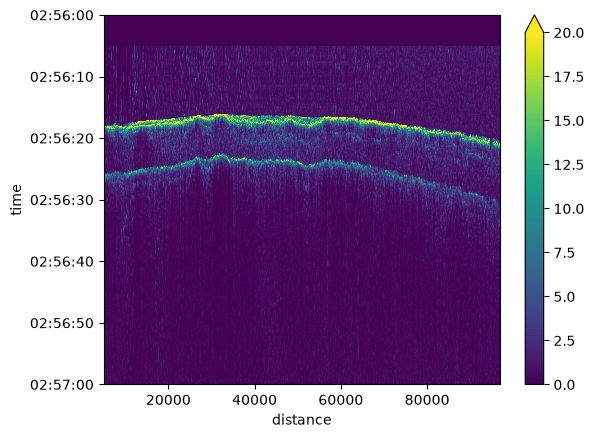

In [16]:
ratio = stalta(processed, sta=0.2, lta=5.0)
ratio.plot(vmin=0, vmax=20, yincrease=False)

`xd.trigger` turns the ratio into picks: a trigger opens when the ratio goes above a
threshold and closes when it falls below half of it; each trigger gives one pick, at its
maximum. The first pick of each channel is the P wave.

**Task:** complete `pick`: trigger on `ratio`, keeping the coordinates needed to locate the
earthquake. The second line, given, keeps the first pick of each channel.

> **Reminder:**
> ```python
> xd.trigger(da, thresh=3.0, coords=["x", "time"])  # a pandas table, one row per pick,
>                                                   # one column per coordinate
> ```

📖 [`xdas.trigger`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.trigger.html)

In [17]:
def pick(ratio, threshold):
    picks = xd.trigger(ratio, thresh=threshold, coords=["distance", "longitude", "latitude", "depth", "time"])
    return picks.sort_values("time").groupby("distance", as_index=False).first()

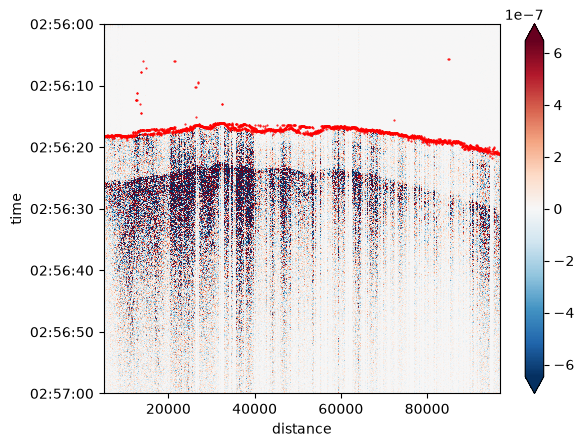

In [18]:
picks = pick(ratio, threshold=8.0)
processed.plot(robust=True, yincrease=False)
plt.plot(picks["distance"], picks["time"], "r.", markersize=1)

## Both cables

**Task:** run the whole chain on both cables: cut one minute around the earthquake (in the sea,
without the dead channels), preprocess, pick, and keep the Wood–Anderson records for the
magnitude.

> **Reminder:** `pd.concat(list_of_dataframes, ignore_index=True)` stacks tables.

In [19]:
keep = {"N": slice(5000, 97000), "S": slice(5000, 130000)}

picks = []
records = {}
for cable in abyss:
    event = abyss[cable].sel(time=slice("2024-09-02T02:56:00", "2024-09-02T02:57:00"), distance=keep[cable]).load()
    processed = preprocess(event)
    picks.append(pick(stalta(processed, sta=0.2, lta=5.0), threshold=8.0))
    records[cable] = wood_anderson(processed)
picks = pd.concat(picks, ignore_index=True)
picks

,distance,longitude,latitude,depth,time,value
0,5101.394453,-71.279206,-29.887853,6.6,2024-09-02 02:56:25.860,14.094495
1,5147.352962,-71.279661,-29.887748,7.1,2024-09-02 02:56:25.960,14.299726
2,5193.311470,-71.280116,-29.887643,7.5,2024-09-02 02:56:18.160,8.083840
3,5239.269979,-71.280570,-29.887539,8.0,2024-09-02 02:56:18.280,13.284948
4,5285.228487,-71.281024,-29.887434,8.3,2024-09-02 02:56:18.120,9.183410
...,...,...,...,...,...,...
4701,129786.828244,-71.842512,-30.718021,1545.7,2024-09-02 02:56:21.900,13.277194
4702,129832.786752,-71.842553,-30.718425,1543.3,2024-09-02 02:56:21.760,17.493732
4703,129878.745261,-71.842594,-30.718829,1540.9,2024-09-02 02:56:22.040,8.960337
4704,129924.703769,-71.842635,-30.719234,1538.5,2024-09-02 02:56:21.680,16.326153


## Location

`locate` (in `tools.py`, read it if you are curious) tries every point of a grid. For each
point, every pick gives an origin time (pick time minus travel time at 7 km/s). At the right
place, all these origin times agree: `locate` keeps the point where they agree best.

Compare with the EMSC location: 71.800°W, 29.954°S, 50 km deep, 02:56:07.37.

In [20]:
location = locate(picks)
location

longitude                           -71.86
latitude                            -29.96
depth                              45000.0
time         2024-09-02 02:56:08.089999999
dtype: object

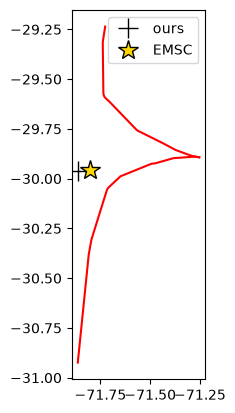

In [21]:
for cable in abyss:
    plt.plot(abyss[cable]["longitude"], abyss[cable]["latitude"], color="red")
plt.plot(location["longitude"], location["latitude"], "k+", markersize=15, label="ours")
plt.plot(-71.800, -29.954, "*", color="gold", markeredgecolor="k", markersize=15, label="EMSC")
plt.gca().set_aspect("equal")
plt.legend()

## Magnitude

The local magnitude (IASPEI formula for California, Hutton & Boore 1987):

$$M_L = \log_{10} A + 1.11 \log_{10} R + 0.00189\, R - 2.09$$

with $A$ the peak Wood–Anderson amplitude in nm and $R$ the hypocentral distance in km. Each
channel gives one estimate.

**Task:** compute `R` and `A` for each channel, then the magnitude. Compare the median with
EMSC (ML 3.4).

> **Reminder:** `to_km(longitude, latitude)` (in `tools.py`) gives flat x, y coordinates in km.
> `np.abs(x).max(axis=0)` is the peak of each column.

In [22]:
x, y = to_km(location["longitude"], location["latitude"])
magnitudes = []
for cable, wa in records.items():
    cx, cy = to_km(wa["longitude"].values, wa["latitude"].values)
    R = np.sqrt((cx - x) ** 2 + (cy - y) ** 2 + ((wa["depth"].values - location["depth"]) / 1000) ** 2)
    A = np.abs(wa.values).max(axis=0) * 1e9  # nm
    magnitudes.append(np.log10(A) + 1.11 * np.log10(R) + 0.00189 * R - 2.09)
magnitudes = np.concatenate(magnitudes)
np.median(magnitudes)

np.float64(3.5794955874733367)

Text(0.5, 0, 'ML')

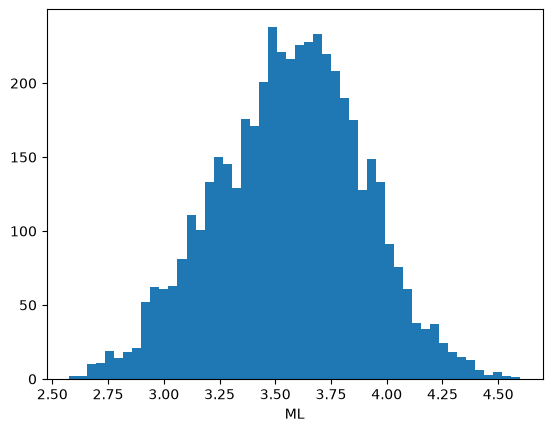

In [23]:
plt.hist(magnitudes, bins=50)
plt.xlabel("ML")